# plot_maps_15k — G6-1.5K-SAI surface-temperature maps (CESM/MIROC/UKESM)

Python port of `plot_maps_15k.m`. Reads the raw G6-1.5K-SAI and baseline
surface-temperature output for three models, builds the 2050–2069 (relative to
the 1.5 K period) maps for SSP2-4.5 and G6-1.5K-SAI, regrids each model onto a
common 1° grid, and forms the multi-model mean/standard-error maps.

Raw NetCDF is read from `/Volumes/D_Visioni2/GeoMIP/G6-1.5K-SAI/`. The result
`G615kSAI` is *created by this script* → written to `data_py/G615kSAI.npz`
(the original `.mat` is left untouched). Maps use the Cartopy helpers in
`mat_utils`; manual MATLAB subplot/colorbar nudges are not pixel-matched.

In [1]:
import sys, os
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import mat_utils as mu
from mat_utils import brewermap, interp2, worldmap, pcolorm, geoshow_coastlines

fold = "/Volumes/D_Visioni2/GeoMIP/G6-1.5K-SAI/"

## Read the three models (ensemble means)

In [2]:
# --- CESM (3 members) ---
nam = "b.e21.BW.f09_g17.SSP245-G6-1p5K-SAI."
nam2 = "b.e21.BWSSP245cmip6.f09_g17.CMIP6-SSP2-4.5-WACCM."
ens = ["001", "002", "003"]
g6 = [mu.ncread(f"{fold}{nam}{e}.cam.h0.TREFHT.203501-208412.nc", "TREFHT") for e in ens]
ta_CESM_g6 = np.stack(g6, axis=-1)
lat_CESM = mu.ncread(f"{fold}{nam}{ens[0]}.cam.h0.TREFHT.203501-208412.nc", "lat")
lon_CESM = mu.ncread(f"{fold}{nam}{ens[0]}.cam.h0.TREFHT.203501-208412.nc", "lon")
sp = [mu.ncread(f"{fold}{nam2}{e}.cam.h0.TREFHT.201501-210012.nc", "TREFHT") for e in ens]
ta_CESM_ssp = np.stack(sp, axis=-1)

# --- MIROC (10 members; MATLAB reuses r01 in slot 2) ---
ens_m = ["r01", "r01", "r03", "r04", "r05", "r06", "r07", "r08", "r09", "r10"]
g6 = [mu.ncread(f"{fold}SurfT_G6-1.5K-SAI_{e}.nc", "SurfT") for e in ens_m]
ta_MIROC_g6 = np.stack(g6, axis=-1)
lat_MIROC = mu.ncread(f"{fold}SurfT_G6-1.5K-SAI_{ens_m[-1]}.nc", "lat")
lon_MIROC = mu.ncread(f"{fold}SurfT_G6-1.5K-SAI_{ens_m[-1]}.nc", "lon")
sp = [mu.ncread(f"{fold}SurfT_Baseline_{e}.nc", "SurfT") for e in ens_m]
ta_MIROC_ssp = np.stack(sp, axis=-1)

# --- UKESM (3 members) ---
# UKESM 'temp' has a singleton level dim (lon,lat,1,time); squeeze it so the
# time axis is axis 2 as in the other models (MATLAB worked on the squeezed array).
ens_u = ["001", "002", "003"]
g6 = [np.squeeze(mu.ncread(f"{fold}T1.5m_G6-1p5K-SAI.{e}.nc", "temp"), axis=2) for e in ens_u]
ta_UKESM_g6 = np.stack(g6, axis=-1)
lat_UKESM = mu.ncread(f"{fold}T1.5m_G6-1p5K-SAI.{ens_u[-1]}.nc", "latitude")
lon_UKESM = mu.ncread(f"{fold}T1.5m_G6-1p5K-SAI.{ens_u[-1]}.nc", "longitude")
sp = [np.squeeze(mu.ncread(f"{fold}T1.5m_SSP245.{e}.nc", "temp"), axis=2) for e in ens_u]
ta_UKESM_ssp = np.stack(sp, axis=-1)

## Ensemble means and time-window zonal maps (1-based MATLAB windows → 0-based)

In [3]:
def emean(x):
    return np.mean(x, axis=-1)

cg, cs = emean(ta_CESM_g6), emean(ta_CESM_ssp)
ta_CESM_g6_zm = np.mean(cg[:, :, 460:600], axis=2)
ta_CESM_ssp_zm = np.mean(cs[:, :, 0:240], axis=2)
ta_CESM_ssp_future_zm = np.mean(cs[:, :, 600:840], axis=2)

mg, ms = emean(ta_MIROC_g6), emean(ta_MIROC_ssp)
ta_MIROC_g6_zm = np.mean(mg[:, :, 460:600], axis=2)
ta_MIROC_ssp_zm = np.mean(ms[:, :, 0:240], axis=2)
ta_MIROC_ssp_future_zm = np.mean(ms[:, :, 540:780], axis=2)

ug, us = emean(ta_UKESM_g6), emean(ta_UKESM_ssp)
ta_UKESM_g6_zm = np.mean(ug[:, :, 472:612], axis=2)
ta_UKESM_ssp_zm = np.mean(us[:, :, 0:240], axis=2)
ta_UKESM_ssp_future_zm = np.mean(us[:, :, 600:840], axis=2)

## Colour scales

In [4]:
fc = brewermap(22, "*RdBu"); mmin, mmax = -1.65 * 3, 1.65 * 3
fca = brewermap(10, "Oranges"); mmax2 = 0.5

## Per-model maps (2050–2069 vs 1.5 K period): SSP2-4.5 (top), G6 (bottom)

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encounter

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encounter

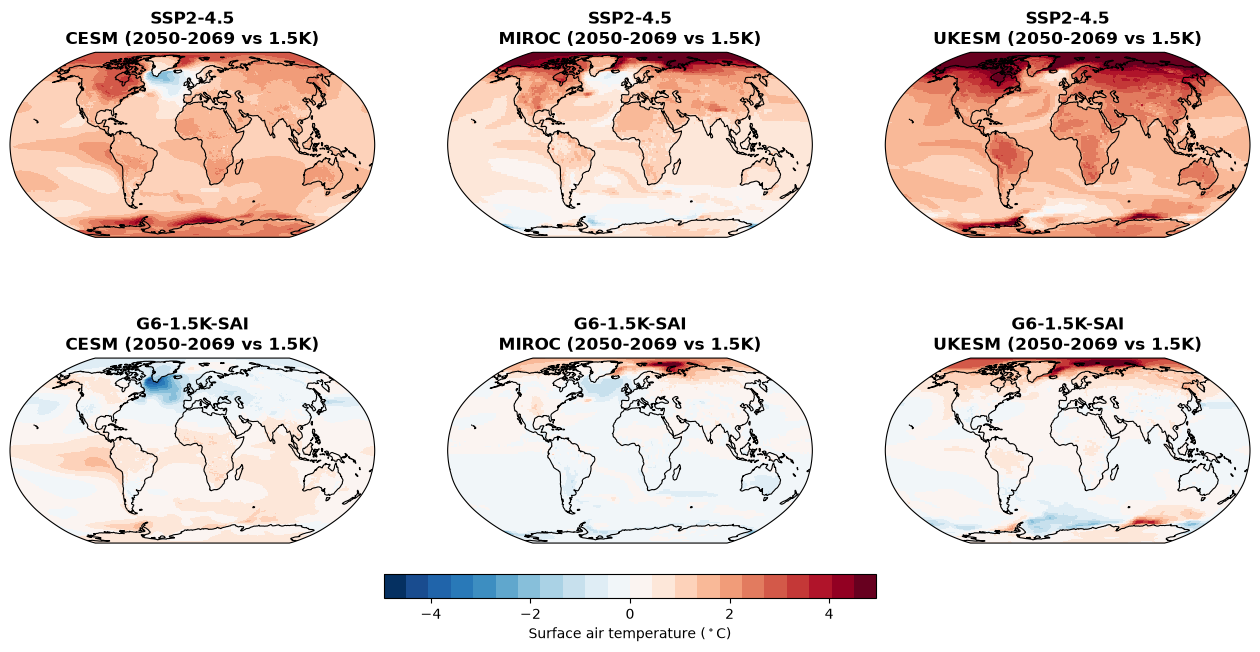

In [5]:
LAT = [lat_CESM, lat_MIROC, lat_UKESM]
LON = [lon_CESM, lon_MIROC, lon_UKESM]
g6_zm = [ta_CESM_g6_zm, ta_MIROC_g6_zm, ta_UKESM_g6_zm]
ba_zm = [ta_CESM_ssp_zm, ta_MIROC_ssp_zm, ta_UKESM_ssp_zm]
sp_zm = [ta_CESM_ssp_future_zm, ta_MIROC_ssp_future_zm, ta_UKESM_ssp_future_zm]
names = ["CESM", "MIROC", "UKESM"]

fig10, axes = plt.subplots(2, 3, figsize=(16, 8),
                           subplot_kw={"projection": ccrs.Robinson()})
for k in range(3):
    for r, (field, tag) in enumerate([(sp_zm[k] - ba_zm[k], "SSP2-4.5"),
                                      (g6_zm[k] - ba_zm[k], "G6-1.5K-SAI")]):
        ax = axes[r, k]; mu.worldmap(ax=ax)
        mp = pcolorm(ax, LAT[k].ravel(), LON[k].ravel(), field.T, cmap=fc, vmin=mmin, vmax=mmax)
        geoshow_coastlines(ax)
        ax.set_title(f"{tag}\n{names[k]} (2050-2069 vs 1.5K)", fontsize=12, fontweight="bold")
fig10.colorbar(mp, ax=axes, orientation="horizontal", fraction=0.04, pad=0.05,
               label=r"Surface air temperature ($^\circ$C)")
plt.show()

## Regrid to a common 1° grid; multi-model mean and standard error

In [6]:
lat_int1 = np.arange(-90, 91, 1.0)
lon_int1 = np.arange(0, 361, 1.0)
nlat, nlon = lat_int1.size, lon_int1.size
sulf_int = np.full((nlat, nlon, 3), np.nan)
ssp_int = np.full((nlat, nlon, 3), np.nan)
for im in range(3):
    lat = LAT[im].ravel(); lon = LON[im].ravel(); lon_ext = np.append(lon, 360.0)
    def regrid(delta):
        d = np.vstack([delta, delta[0:1, :]])
        return interp2(lon_ext, lat, d.T, lon_int1, lat_int1, "linear", np.nan)
    sulf_int[:, :, im] = regrid(g6_zm[im] - ba_zm[im])
    ssp_int[:, :, im] = regrid(sp_zm[im] - ba_zm[im])

sulf_delta_all1 = np.nanmean(sulf_int, axis=2)
ssp5_delta_all1 = np.nanmean(ssp_int, axis=2)
sulf_delta_std1 = np.nanstd(sulf_int, axis=2, ddof=1) / 3
ssp5_delta_std1 = np.nanstd(ssp_int, axis=2, ddof=1) / 3

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


## Save G615kSAI (object arrays shaped (1,3) to mirror the MATLAB cells)

In [7]:
def cell13(lst):
    o = np.empty((1, 3), dtype=object)
    for i, v in enumerate(lst):
        o[0, i] = np.asarray(v)
    return o

mu.save_npz("G615kSAI",
            LAT=cell13([l.ravel() for l in LAT]),
            LON=cell13([l.ravel() for l in LON]),
            ta_g6=cell13(g6_zm), ta_ba=cell13(ba_zm), ta_sp=cell13(sp_zm),
            sulf_delta_all1=sulf_delta_all1, ssp5_delta_all1=ssp5_delta_all1)
print("saved data_py/G615kSAI.npz")

saved data_py/G615kSAI.npz


## Multi-model mean / standard-error maps

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encounter

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


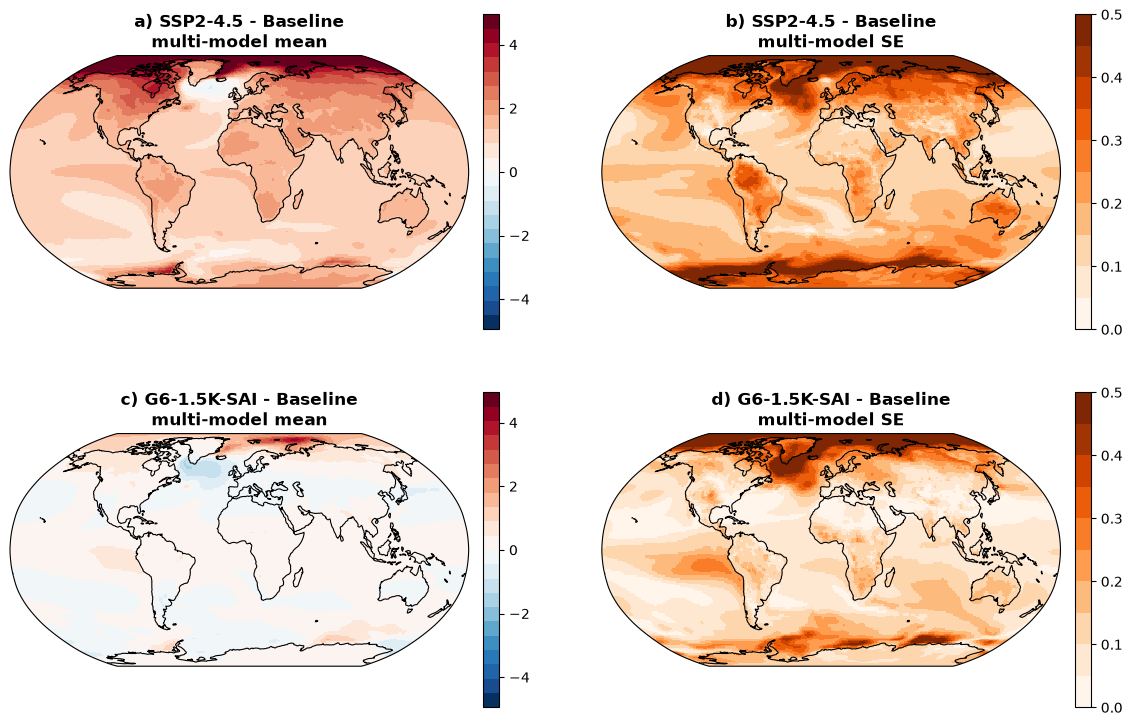

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encounter

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


done


In [8]:
fig15, axes = plt.subplots(2, 2, figsize=(14, 9),
                           subplot_kw={"projection": ccrs.Robinson()})
panels = [(ssp5_delta_all1, fc, mmin, mmax, "a) SSP2-4.5 - Baseline\nmulti-model mean"),
          (np.abs(ssp5_delta_std1), fca, 0, mmax2, "b) SSP2-4.5 - Baseline\nmulti-model SE"),
          (sulf_delta_all1, fc, mmin, mmax, "c) G6-1.5K-SAI - Baseline\nmulti-model mean"),
          (np.abs(sulf_delta_std1), fca, 0, mmax2, "d) G6-1.5K-SAI - Baseline\nmulti-model SE")]
for ax, (Z, cm, vmn, vmx, ttl) in zip(axes.ravel(), panels):
    mu.worldmap(ax=ax)
    mp = pcolorm(ax, lat_int1, lon_int1, Z, cmap=cm, vmin=vmn, vmax=vmx)
    geoshow_coastlines(ax)
    ax.set_title(ttl, fontsize=12, fontweight="bold")
    fig15.colorbar(mp, ax=ax, orientation="vertical", fraction=0.04, pad=0.03)
plt.show()
os.makedirs("py_outputs", exist_ok=True)
fig15.savefig("py_outputs/maps_mean_15k.png", dpi=300, bbox_inches="tight")
print("done")